# Lab 2 · Part I: Neural Networks and Regression

We fit small fully connected networks (MLPs) to
- **(a)** a synthetic 1-D polynomial, and
- **(b)** a real UCI regression dataset (Automobile, as in Lab 1),

and look at how depth, width, activation, weight decay and the complexity of the target change the fit.
For regression, "accuracy" means **MSE** (the training loss) and **R²**, both on train and test.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

torch.manual_seed(0)
torch.set_num_threads(4)  # tiny models: CPU beats GPU/MPS here
pd.options.display.float_format = "{:.4g}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Polynomial toy data

`eval_poly(x, c)` evaluates an order-$p$ polynomial (Horner's rule). A polynomial with random coefficients is almost
flat on $[-1, 1]$ for large $p$, so `random_poly` instead puts the $p$ roots at slightly jittered Chebyshev nodes.
That way a higher order really means more wiggles ($p-1$ turning points over the whole interval). Each polynomial
is scaled to $\max_{[-1,1]}|f| = 1$, so MSEs are comparable across $p$.

Data:
- 1,000 points, $x \sim U(-1, 1)$
- $y = f(x) + \varepsilon$, $\varepsilon \sim \mathcal N(0, 0.02^2)$
- 80/20 train/test split
- the noise variance $4\cdot10^{-4}$ is the best test MSE we can hope for

p = 3 coefficients, highest degree first: [ 2.355 -0.308 -1.55   0.113]
800 training / 200 test points
noise-only MSE (true f vs data): train 4.02e-04 | test 4.96e-04


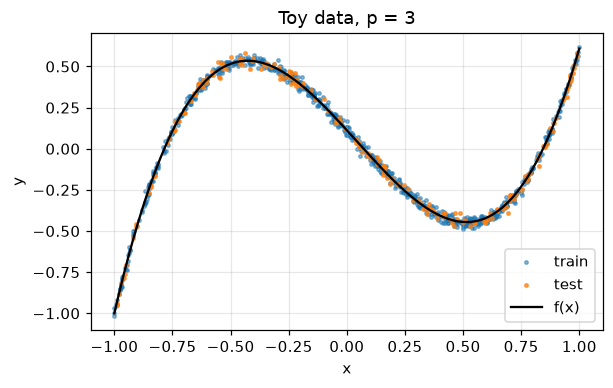

In [2]:
def eval_poly(x, c):
    # Horner's rule, c[0] is the highest-degree coefficient
    out = np.zeros_like(x, dtype=float)
    for ck in c:
        out = out * x + ck
    return out

def random_poly(p, seed=0):
    rng = np.random.default_rng(seed)
    k = np.arange(1, p + 1)
    roots = np.cos((2 * k - 1 + rng.uniform(-0.3, 0.3, p)) * np.pi / (2 * p))
    c = np.poly(roots)
    return c / np.abs(eval_poly(np.linspace(-1, 1, 2001), c)).max()

SIGMA = 0.02

def col(a):
    t = torch.tensor(np.asarray(a), dtype=torch.float32)
    return t.unsqueeze(1) if t.ndim == 1 else t

def toy_data(p, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    c = random_poly(p, seed)
    x = rng.uniform(-1, 1, n)
    y = eval_poly(x, c) + SIGMA * rng.standard_normal(n)
    x_a, x_b, y_a, y_b = train_test_split(x, y, test_size=0.2, random_state=seed)
    return c, tuple(map(col, (x_a, y_a, x_b, y_b)))

poly_c, toy = toy_data(p=3)
Xtr, ytr, Xte, yte = toy
print("p = 3 coefficients, highest degree first:", np.round(poly_c, 3))
print(f"{len(Xtr)} training / {len(Xte)} test points")
true_mse = lambda X, y: np.mean((eval_poly(X[:, 0].numpy(), poly_c) - y[:, 0].numpy()) ** 2)
print(f"noise-only MSE (true f vs data): train {true_mse(Xtr, ytr):.2e} | test {true_mse(Xte, yte):.2e}")

xs = np.linspace(-1, 1, 400)
plt.figure(figsize=(6, 3.5))
plt.scatter(Xtr, ytr, s=5, alpha=0.5, label="train")
plt.scatter(Xte, yte, s=5, alpha=0.7, label="test")
plt.plot(xs, eval_poly(xs, poly_c), "k", lw=1.5, label="f(x)")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Toy data, p = 3"); plt.legend()
plt.show()

## 2. The network before training

`FeedForward` stacks `Linear` layers of width $m$ with an activation in between and a linear output. Default:
2 hidden layers, $m = 64$, ReLU, PyTorch's default random (Kaiming-uniform) initialization.

FeedForward(
  (body): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
trainable parameters: 4353


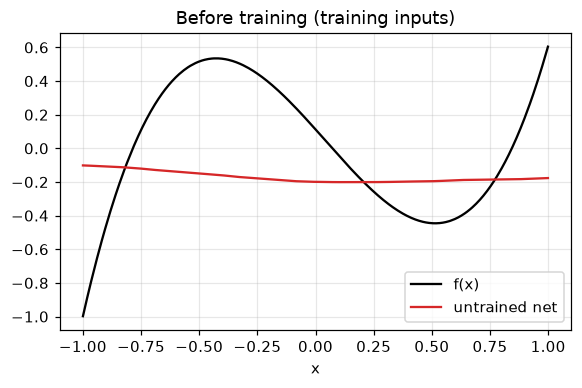

MSE before training: 0.1649


In [3]:
class FeedForward(nn.Module):
    def __init__(self, d_in=1, widths=(64, 64), act=nn.ReLU):
        super().__init__()
        blocks, d = [], d_in
        for w in widths:
            blocks += [nn.Linear(d, w), act()]
            d = w
        blocks.append(nn.Linear(d, 1))
        self.body = nn.Sequential(*blocks)

    def forward(self, x):
        return self.body(x)

def count_params(net):
    return sum(w.numel() for w in net.parameters())

torch.manual_seed(0)
net = FeedForward()
print(net)
print("trainable parameters:", count_params(net))

srt = Xtr[:, 0].argsort()
with torch.no_grad():
    out0 = net(Xtr)
plt.figure(figsize=(6, 3.5))
plt.plot(Xtr[srt], eval_poly(Xtr[srt, 0].numpy(), poly_c), "k", label="f(x)")
plt.plot(Xtr[srt], out0[srt], "C3", label="untrained net")
plt.xlabel("x"); plt.title("Before training (training inputs)"); plt.legend()
plt.show()
print(f"MSE before training: {F.mse_loss(out0, ytr).item():.4f}")

**Observations.** The untrained net is basically a flat, slightly tilted line. Its output is small and only mildly
piecewise linear in $x$, and it has nothing to do with $f$: its MSE is about $\mathrm{Var}(y)$, same as guessing a constant.

## 3. Training with MSE

**Gradients:** `loss.backward()` does backpropagation, i.e. it applies the chain rule from the MSE loss back through
every layer and stores $\partial L/\partial\theta$ in each parameter's `.grad`.
**Updates:** mini-batches of 32 (reshuffled every epoch) with Adam, learning rate $10^{-3}$. Adam is SGD
($\theta \leftarrow \theta - \eta g$) with momentum and a per-parameter step size. Weight decay $\lambda$ just adds
$\lambda\theta$ to the gradient.

A quick check that autograd agrees with the hand-computed gradient of the last layer, and that an SGD step is $\theta - \eta g$:

In [4]:
torch.manual_seed(0)
chk = FeedForward()
xb, yb = Xtr[:32], ytr[:32]
feats = chk.body[:-1](xb)                   # input to the last Linear layer
F.mse_loss(chk(xb), yb).backward()
g_out = 2 / len(xb) * (chk(xb) - yb)        # dL/d(prediction)
W = chk.body[-1].weight
print("manual gradient == autograd:", torch.allclose(g_out.T @ feats, W.grad, atol=1e-6))

W_before = W.detach().clone()
torch.optim.SGD(chk.parameters(), lr=0.1).step()
print("SGD update == W - 0.1 * grad:", torch.allclose(W, W_before - 0.1 * W.grad))

manual gradient == autograd: True


SGD update == W - 0.1 * grad: True


`fit` records train/test MSE and R² after **every** epoch; we print some of the epochs and plot all of them.

ep   1  train: MSE 1.06e-01, R2 0.2378   test: MSE 1.24e-01, R2 0.1734
ep   2  train: MSE 8.17e-02, R2 0.4102   test: MSE 9.68e-02, R2 0.3569
ep   3  train: MSE 5.76e-02, R2 0.5842   test: MSE 6.79e-02, R2 0.5491
ep   4  train: MSE 3.28e-02, R2 0.7631   test: MSE 3.98e-02, R2 0.7354
ep   5  train: MSE 1.57e-02, R2 0.8866   test: MSE 2.12e-02, R2 0.8594
ep  25  train: MSE 9.64e-04, R2 0.9930   test: MSE 1.27e-03, R2 0.9916


ep  50  train: MSE 4.52e-04, R2 0.9967   test: MSE 5.89e-04, R2 0.9961
ep  75  train: MSE 5.05e-04, R2 0.9964   test: MSE 6.38e-04, R2 0.9958


ep 100  train: MSE 7.02e-04, R2 0.9949   test: MSE 7.52e-04, R2 0.9950
ep 125  train: MSE 5.25e-04, R2 0.9962   test: MSE 7.24e-04, R2 0.9952


ep 150  train: MSE 5.16e-04, R2 0.9963   test: MSE 6.30e-04, R2 0.9958
ep 175  train: MSE 4.66e-04, R2 0.9966   test: MSE 5.63e-04, R2 0.9963


ep 200  train: MSE 4.90e-04, R2 0.9965   test: MSE 6.43e-04, R2 0.9957


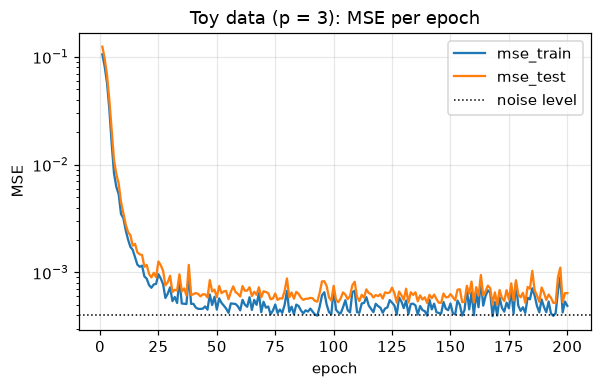

In [5]:
def score(net, X, y):
    net.eval()
    with torch.no_grad():
        mse = F.mse_loss(net(X), y).item()
    return mse, 1 - mse / y.var(unbiased=False).item()

def fit(net, splits, epochs=200, lr=1e-3, bs=32, wd=0.0, log_every=None):
    Xa, ya, Xb, yb = splits
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    rows = []
    for ep in range(1, epochs + 1):
        net.train()
        shuffle = torch.randperm(len(Xa))
        for s in range(0, len(Xa), bs):
            b = shuffle[s:s + bs]
            loss = F.mse_loss(net(Xa[b]), ya[b])
            opt.zero_grad(); loss.backward(); opt.step()
        rows.append((ep, *score(net, Xa, ya), *score(net, Xb, yb)))
        if log_every and (ep <= 5 or ep % log_every == 0):
            print("ep {:3d}  train: MSE {:.2e}, R2 {:.4f}   test: MSE {:.2e}, R2 {:.4f}".format(*rows[-1]))
    return pd.DataFrame(rows, columns=["epoch", "mse_train", "r2_train", "mse_test", "r2_test"]).set_index("epoch")

def plot_history(log, title, floor=None):
    ax = log[["mse_train", "mse_test"]].plot(logy=True, figsize=(6, 3.5), title=title)
    if floor:
        ax.axhline(floor, color="k", ls=":", lw=1, label="noise level")
    ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend()
    plt.show()

torch.manual_seed(0)
net = FeedForward()
log = fit(net, toy, log_every=25)
plot_history(log, "Toy data (p = 3): MSE per epoch", floor=SIGMA**2)

The trained net on the **test** inputs, and what it does outside $[-1, 1]$:

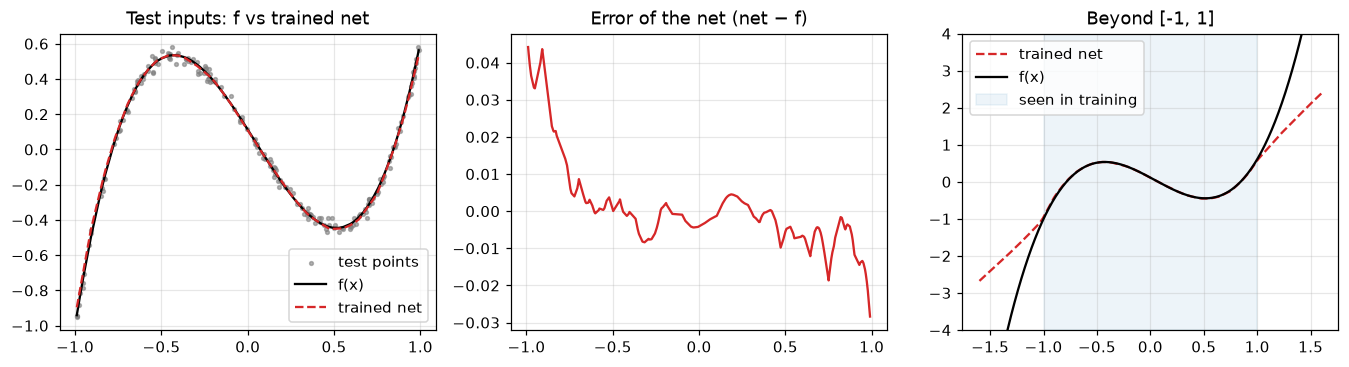

In [6]:
srt = Xte[:, 0].argsort()
x_s = Xte[srt, 0].numpy()
f_s = eval_poly(x_s, poly_c)
with torch.no_grad():
    pred = net(Xte)[srt, 0]

fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
axs[0].scatter(x_s, yte[srt, 0], s=6, c="gray", alpha=0.6, label="test points")
axs[0].plot(x_s, f_s, "k", label="f(x)")
axs[0].plot(x_s, pred, "C3--", label="trained net")
axs[0].set_title("Test inputs: f vs trained net"); axs[0].legend()
axs[1].plot(x_s, pred.numpy() - f_s, "C3")
axs[1].set_title("Error of the net (net − f)")
x_far = np.linspace(-1.6, 1.6, 400)
with torch.no_grad():
    axs[2].plot(x_far, net(col(x_far))[:, 0], "C3--", label="trained net")
axs[2].plot(x_far, eval_poly(x_far, poly_c), "k", label="f(x)")
axs[2].axvspan(-1, 1, color="C0", alpha=0.08, label="seen in training")
axs[2].set_ylim(-4, 4); axs[2].set_title("Beyond [-1, 1]"); axs[2].legend()
plt.show()

**Observations.**
- After ~40 epochs the net is at train MSE ≈ $4.5\cdot10^{-4}$, test R² ≈ 0.996. The true $f$ itself gets
  $4.0\cdot10^{-4}$ (train) and $5.0\cdot10^{-4}$ (test), so the net is at the noise level. The small train/test
  gap is just the test noise, not overfitting.
- The curves are jumpy because Adam runs on mini-batches with a constant learning rate. A decaying rate would smooth this.
- The error is largest near $x = \pm1$, where $f$ is steepest and there is data on one side only.
- Outside the training range a ReLU net is linear, so it goes on as a straight line while the cubic takes off.
  It only knows $f$ where it has seen data.

### Should we use ℓ2 regularization (weight decay)?

Weight decay pulls the weights towards zero. It trades some bias for less variance, so it only helps if the model
overfits. We try a few values of $\lambda$ (3 seeds each):

In [7]:
def compare(variants, splits, seeds=(0, 1, 2), **fit_kw):
    # variants: {label: FeedForward kwargs, optionally "wd"} -> seed-averaged final metrics, plus the last net per label
    out, nets = [], {}
    for label, kw in variants.items():
        kw = dict(kw)
        wd = kw.pop("wd", 0.0)
        last = []
        for s in seeds:
            torch.manual_seed(s)
            m = FeedForward(splits[0].shape[1], **kw)
            last.append(fit(m, splits, wd=wd, **fit_kw).iloc[-1])
        last = pd.DataFrame(last)
        nets[label] = m
        out.append({"model": label, "params": count_params(m),
                    "mse_train": last.mse_train.mean(), "mse_test": last.mse_test.mean(),
                    "mse_test_sd": last.mse_test.std(), "r2_test": last.r2_test.mean()})
    return pd.DataFrame(out).set_index("model"), nets

wd_res, _ = compare({f"wd {wd:g}": dict(wd=wd) for wd in [0, 1e-4, 1e-3, 1e-2, 1e-1]}, toy)
wd_res

,params,mse_train,mse_test,mse_test_sd,r2_test
model,,,,,
wd 0,4353,0.0004811,0.0006309,2.468e-05,0.9958
wd 0.0001,4353,0.0005103,0.0006596,7.164e-05,0.9956
wd 0.001,4353,0.001219,0.001465,0.0002451,0.9903
wd 0.01,4353,0.01186,0.0159,0.001154,0.8944
wd 0.1,4353,0.1385,0.1516,0.000118,-0.006451


**Answer: no, not here.** Without weight decay the train error is already at the noise level, so there is no
overfitting to fix. $\lambda = 10^{-4}$ changes nothing, and anything bigger only adds bias: R² drops to 0.89 at
$\lambda = 10^{-2}$, and at $\lambda = 10^{-1}$ the net collapses to the mean (R² ≈ 0). Weight decay is worth it when
the model can fit the noise (little or noisy data, many inputs or parameters, see the Automobile data below), and then
$\lambda$ should be tuned on validation data. With Adam, `AdamW` (decoupled weight decay) is usually the better choice.

## 4. Architecture and polynomial order

Defaults: 2 hidden layers × 64, ReLU, Adam (lr $10^{-3}$), 200 epochs, no weight decay, mean over 3 seeds.

**Number of hidden layers** (width 64):

In [8]:
depth_res, _ = compare({f"{d} layer(s)": dict(widths=(64,) * d) for d in [1, 2, 3, 4]}, toy)
depth_res

,params,mse_train,mse_test,mse_test_sd,r2_test
model,,,,,
1 layer(s),193,0.0004856,0.0006375,2.808e-05,0.9958
2 layer(s),4353,0.0004811,0.0006309,2.468e-05,0.9958
3 layer(s),8513,0.0004676,0.0005963,4.149e-05,0.996
4 layer(s),12673,0.0005572,0.0007407,9.151e-05,0.9951


**Activation function:**

In [9]:
activations = {"ReLU": nn.ReLU, "LeakyReLU": nn.LeakyReLU, "GELU": nn.GELU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}
act_res, act_nets = compare({k: dict(act=a) for k, a in activations.items()}, toy)
act_res

,params,mse_train,mse_test,mse_test_sd,r2_test
model,,,,,
ReLU,4353,0.0004811,0.0006309,2.468e-05,0.9958
LeakyReLU,4353,0.0004912,0.0006238,3.931e-05,0.9959
GELU,4353,0.0004594,0.0005645,3.58e-06,0.9963
Tanh,4353,0.0004475,0.0005803,1.988e-05,0.9961
Sigmoid,4353,0.005403,0.006766,0.001779,0.9551


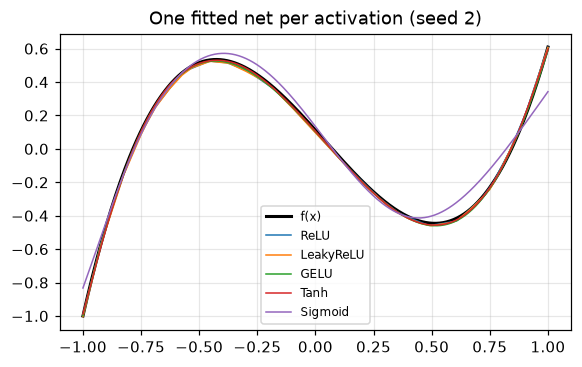

In [10]:
xs_t = col(xs)
plt.figure(figsize=(6, 3.5))
plt.plot(xs, eval_poly(xs, poly_c), "k", lw=2, label="f(x)")
for label, m in act_nets.items():
    with torch.no_grad():
        plt.plot(xs, m(xs_t)[:, 0], lw=1, label=label)
plt.title("One fitted net per activation (seed 2)"); plt.legend(fontsize=8)
plt.show()

**Number of parameters** (2 hidden layers of width $m$):

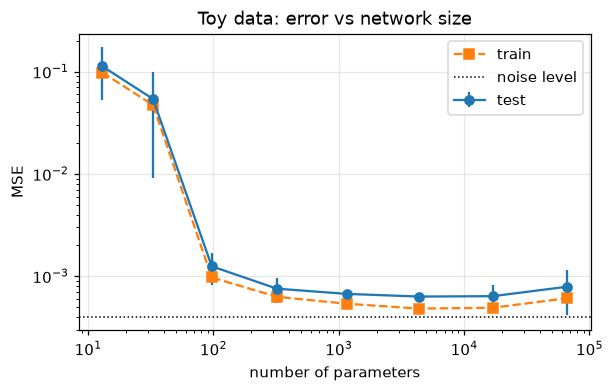

,params,mse_train,mse_test,mse_test_sd,r2_test
model,,,,,
width 2,13,0.09794,0.1127,0.06024,0.2516
width 4,33,0.04706,0.05392,0.04473,0.6419
width 8,97,0.0009695,0.001246,0.0004292,0.9917
width 16,321,0.0006272,0.0007531,0.0002087,0.995
width 32,1153,0.0005363,0.0006698,5.438e-05,0.9956
width 64,4353,0.0004811,0.0006309,2.468e-05,0.9958
width 128,16897,0.00049,0.0006358,0.0001807,0.9958
width 256,66561,0.0006083,0.0007874,0.0003723,0.9948


In [11]:
width_res, _ = compare({f"width {w}": dict(widths=(w, w)) for w in [2, 4, 8, 16, 32, 64, 128, 256]}, toy)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(width_res.params, width_res.mse_test, yerr=width_res.mse_test_sd, marker="o", label="test")
ax.plot(width_res.params, width_res.mse_train, "s--", label="train")
ax.axhline(SIGMA**2, color="k", ls=":", lw=1, label="noise level")
ax.set(xscale="log", yscale="log", xlabel="number of parameters", ylabel="MSE", title="Toy data: error vs network size")
ax.legend(); plt.show()
width_res

**Observations (p = 3).**
- **Depth:** 1 to 4 hidden layers all hit the noise level, and the differences are within the seed spread. One hidden
  layer (193 parameters) is plenty for a cubic. With the same learning rate and epochs, 4 layers is a bit worse and less stable.
- **Activation:** ReLU, LeakyReLU, GELU and Tanh are all at the noise level, with the smooth ones (GELU, Tanh) slightly
  ahead: the target is smooth, while a ReLU fit has small kinks. Sigmoid is 10× worse and the least stable. It saturates,
  isn't zero-centred and its derivative is at most 1/4, so gradients shrink layer by layer and 200 epochs aren't enough.
- **Width:** $m = 2$ and $4$ underfit badly and depend a lot on the seed (too few linear pieces, and a few dead ReLUs
  wipe out most of the capacity). From $m = 8$ (~100 parameters) we are close to the noise level, and past $m \approx 64$
  nothing improves. Even 66k parameters for 800 points does **not** overfit: with this little noise, gradient training
  still ends up at a smooth function.

**Polynomial order $p$.** Same recipe for $p \in \{1, 3, 5, 9, 15, 21\}$, with the default net (2×64) and a deeper,
wider one (3×128):

In [12]:
ORDERS = [1, 3, 5, 9, 15, 21]
archs = {"2x64": dict(widths=(64, 64)), "3x128": dict(widths=(128, 128, 128))}
parts, by_order = [], {}
for p in ORDERS:
    c, splits = toy_data(p)
    res, nets = compare(archs, splits)
    parts.append(res.assign(p=p).reset_index())
    by_order[p] = (c, nets)
order_res = pd.concat(parts).pivot(index="p", columns="model", values=["mse_train", "mse_test", "r2_test"])
order_res

mse_train            mse_test           r2_test       
model      2x64     3x128      2x64     3x128    2x64  3x128
p                                                           
1      0.000425 0.0005117 0.0005287 0.0006278  0.9981 0.9977
3     0.0004811 0.0005257 0.0006309 0.0006102  0.9958 0.9959
5     0.0009284 0.0008732  0.001023  0.001095  0.9946 0.9942
9      0.008146  0.003594  0.008113  0.003349  0.9622 0.9844
15      0.02391  0.009353   0.02822  0.009442  0.8445  0.948
21      0.09901   0.01398    0.1143   0.02297  0.3456 0.8684

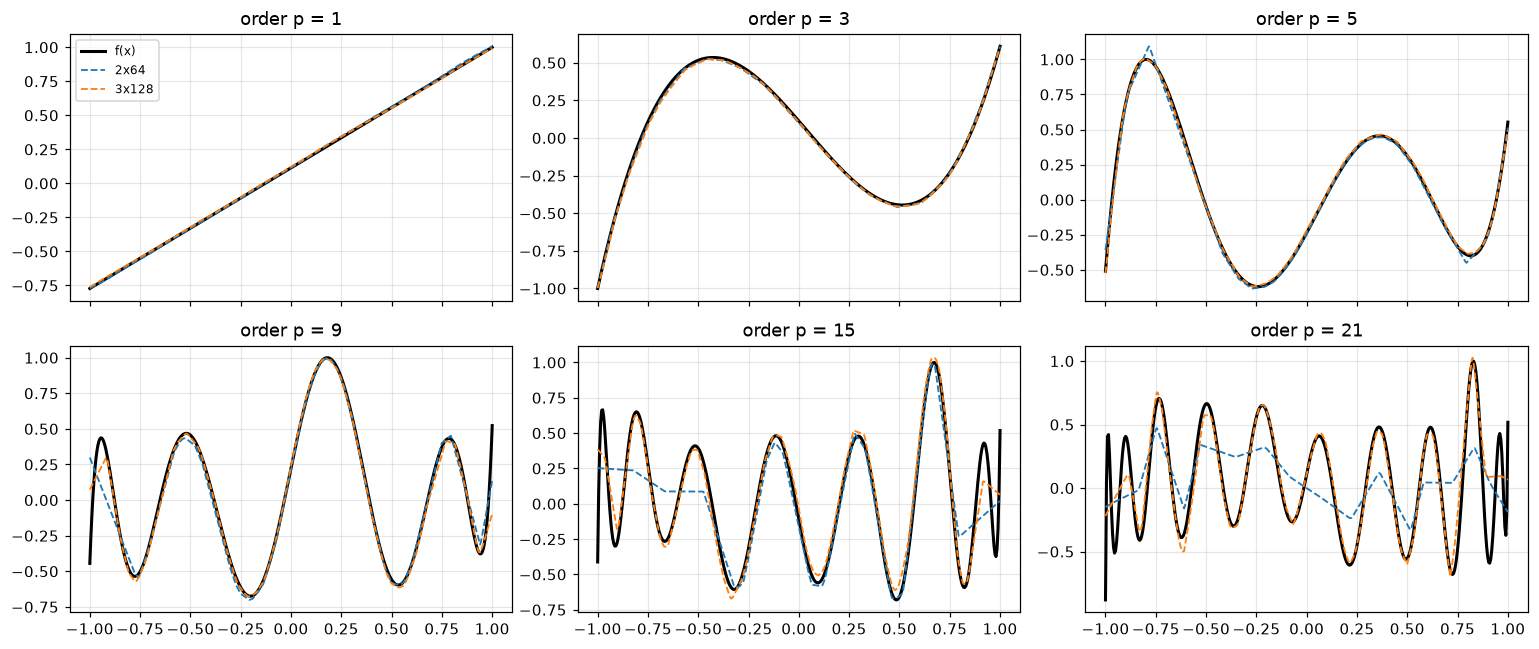

In [13]:
fig, axs = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, p in zip(axs.flat, ORDERS):
    c, nets = by_order[p]
    ax.plot(xs, eval_poly(xs, c), "k", lw=2, label="f(x)")
    for label, m in nets.items():
        with torch.no_grad():
            ax.plot(xs, m(xs_t)[:, 0], "--", lw=1.2, label=label)
    ax.set_title(f"order p = {p}")
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observations.**
- Up to $p = 5$ both nets reach the noise level. From $p = 9$ the 2×64 net underfits (train ≈ test error, so it's
  bias, not variance), and at $p = 21$ it basically fails (R² 0.35) and smooths over most of the wiggles.
- The 3×128 net is 2-5× better for $p \ge 9$ and still reaches R² 0.87 at $p = 21$. A ReLU net needs roughly one linear
  piece per bend of $f$, so more wiggles need more capacity, and adding depth multiplies the number of pieces much
  faster than adding width.
- Both nets lose the outermost wiggles first. The roots are densest near $\pm1$, so $f$ oscillates fastest exactly
  where there is data on one side only.
- The net never sees the coefficients. In the monomial basis they blow up with $p$ (around $10^6$ for $p = 21$), so
  fitting the polynomial directly would be badly conditioned. For the net, only how wiggly $f$ is matters.

## 5. Real data: UCI Automobile

[Automobile](https://archive.ics.uci.edu/dataset/10/automobile) (1985 Ward's Automotive Yearbook), the small regression
dataset we already used in Lab 1: 205 cars, 25 features (size, weight, engine, fuel system, make, ...), target `price`
in $. The 4 cars without a price are dropped, which leaves 201.

Preprocessing as in Lab 1: an 80/20 split stratified on price quintiles (prices are skewed, and with only ~40 test cars
the score otherwise depends a lot on how many expensive ones land there). Missing values get the training median, and
the 8 categorical columns are one-hot encoded. Inputs and target are standardized with training statistics; the net
trains on the standardized price, and we also report RMSE in $. Ordinary least squares is the baseline.

In [14]:
csv = Path("data/automobile.csv")
if not csv.exists():
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=10)
    csv.parent.mkdir(exist_ok=True)
    pd.concat([ds.data.features, ds.data.targets], axis=1).to_csv(csv, index=False)
cars = pd.read_csv(csv).dropna(subset=["price"]).reset_index(drop=True)
price = cars.pop("price").to_numpy()
cat_cols = list(cars.select_dtypes(exclude="number").columns)
print(f"{len(cars)} cars with a price, {cars.shape[1]} features, {len(cat_cols)} of them categorical: {', '.join(cat_cols)}")
display(pd.Series(price, name="price ($)").describe().to_frame().T)

c_tr, c_te, p_tr, p_te = train_test_split(cars, price, test_size=0.2, random_state=42,
                                          stratify=pd.qcut(price, 5, labels=False))
medians = c_tr.median(numeric_only=True)
one_hot = lambda df: pd.get_dummies(df.fillna(medians), columns=cat_cols, dtype=float)
A = one_hot(c_tr)
B = one_hot(c_te).reindex(columns=A.columns, fill_value=0.0)
print(f"after one-hot encoding: {A.shape[1]} inputs | {len(A)} train / {len(B)} test cars")

sx, sy = StandardScaler().fit(A), StandardScaler().fit(p_tr[:, None])
USD = sy.scale_[0]  # std of the training prices in $
real = (col(sx.transform(A)), col(sy.transform(p_tr[:, None])),
        col(sx.transform(B)), col(sy.transform(p_te[:, None])))

def to_usd(mse):  # MSE on the standardized price -> RMSE in $
    return np.sqrt(mse) * USD

lin = LinearRegression().fit(real[0], real[1])
lin_mse = F.mse_loss(torch.tensor(lin.predict(real[2]), dtype=torch.float32), real[3]).item()
print(f"OLS baseline on test: RMSE ${to_usd(lin_mse):,.0f}, R2 {lin.score(real[2], real[3]):.3f}")

201 cars with a price, 25 features, 8 of them categorical: fuel-system, engine-type, engine-location, drive-wheels, body-style, aspiration, fuel-type, make


,count,mean,std,min,25%,50%,75%,max
price ($),201,1.321e+04,7947,5118,7775,1.03e+04,1.65e+04,4.54e+04


after one-hot encoding: 67 inputs | 160 train / 41 test cars
OLS baseline on test: RMSE $1,868, R2 0.938


**Step 2 again: the untrained net.** With 67 inputs we can't plot the function itself, so we plot predicted vs
actual price on the training set.

8577 parameters | train RMSE before training: $8,042


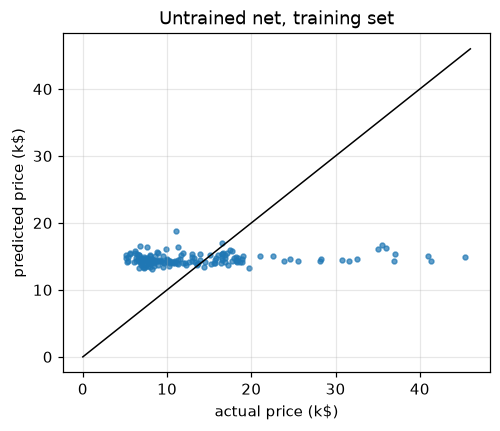

In [15]:
def scatter_pred(nets, X, y, titles):
    fig, axs = plt.subplots(1, len(nets), figsize=(5 * len(nets), 4), squeeze=False)
    actual = sy.inverse_transform(y.numpy())[:, 0] / 1000
    for ax, m, t in zip(axs[0], nets, titles):
        with torch.no_grad():
            guess = sy.inverse_transform(m(X).numpy())[:, 0] / 1000
        ax.scatter(actual, guess, s=10, alpha=0.7)
        ax.plot([0, 46], [0, 46], "k", lw=1)
        ax.set(xlabel="actual price (k$)", ylabel="predicted price (k$)", title=t)
    plt.show()

torch.manual_seed(0)
rnet = FeedForward(d_in=real[0].shape[1])
print(f"{count_params(rnet)} parameters | train RMSE before training: ${to_usd(score(rnet, real[0], real[1])[0]):,.0f}")
scatter_pred([rnet], real[0], real[1], ["Untrained net, training set"])

**Step 3 again: training.** 300 epochs (only 5 mini-batches per epoch with 160 cars), everything else as for the polynomial.

ep   1  train: MSE 7.82e-01, R2 0.2177   test: MSE 6.90e-01, R2 0.2020
ep   2  train: MSE 5.84e-01, R2 0.4156   test: MSE 5.06e-01, R2 0.4154
ep   3  train: MSE 3.84e-01, R2 0.6163   test: MSE 3.32e-01, R2 0.6164
ep   4  train: MSE 2.20e-01, R2 0.7799   test: MSE 1.98e-01, R2 0.7714
ep   5  train: MSE 1.30e-01, R2 0.8697   test: MSE 1.40e-01, R2 0.8384


ep  50  train: MSE 8.54e-03, R2 0.9915   test: MSE 7.12e-02, R2 0.9177


ep 100  train: MSE 6.22e-03, R2 0.9938   test: MSE 7.30e-02, R2 0.9156


ep 150  train: MSE 5.26e-03, R2 0.9947   test: MSE 7.95e-02, R2 0.9080


ep 200  train: MSE 4.72e-03, R2 0.9953   test: MSE 7.93e-02, R2 0.9084


ep 250  train: MSE 4.38e-03, R2 0.9956   test: MSE 8.06e-02, R2 0.9068


ep 300  train: MSE 5.40e-03, R2 0.9946   test: MSE 7.76e-02, R2 0.9103

after 300 epochs: RMSE train $591 / test $2,238, test R2 0.910
lowest test MSE at epoch 10: RMSE $1,735


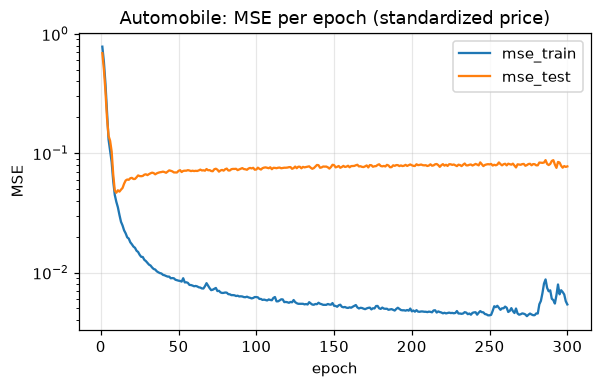

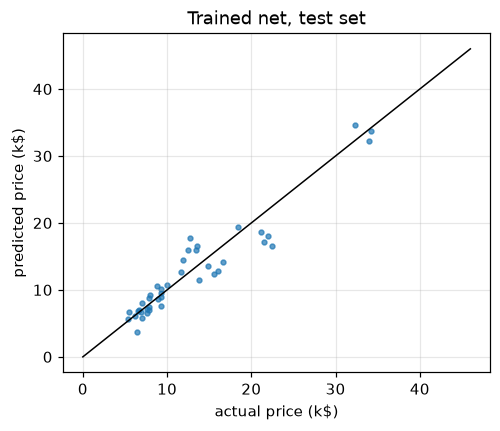

In [16]:
R_EPOCHS = 300
rlog = fit(rnet, real, epochs=R_EPOCHS, log_every=50)
end = rlog.iloc[-1]
print(f"\nafter {R_EPOCHS} epochs: RMSE train ${to_usd(end.mse_train):,.0f} / test ${to_usd(end.mse_test):,.0f}, test R2 {end.r2_test:.3f}")
print(f"lowest test MSE at epoch {rlog.mse_test.idxmin()}: RMSE ${to_usd(rlog.mse_test.min()):,.0f}")
plot_history(rlog, "Automobile: MSE per epoch (standardized price)")
scatter_pred([rnet], real[2], real[3], ["Trained net, test set"])

**Observations.**
- Untrained, the net is no better than a constant guess: its train RMSE ($8,042) is about the std of the prices ($7,947).
- Training is fast: R² passes 0.99 on train by epoch 50. On test it gets stuck around 0.91: the lowest test error
  is at epoch 10 ($1,735), and after that the test MSE drifts slowly up while the train MSE keeps falling.
  After 300 epochs: train RMSE $591, test $2,238.
- That's textbook overfitting. 160 cars and 67 inputs are no match for 8.6k parameters, so the net memorizes the
  training prices. It also doesn't beat plain OLS ($1,868, R² 0.94): price here is mostly a linear function of size,
  weight and engine, so there isn't much nonlinearity to gain from.

In [17]:
def in_usd(res):  # RMSE in $; the _sd column is the seed std (delta method)
    return res.assign(rmse_train=to_usd(res.mse_train), rmse_test=to_usd(res.mse_test),
                      rmse_test_sd=USD * res.mse_test_sd / (2 * np.sqrt(res.mse_test)))[
        ["params", "rmse_train", "rmse_test", "rmse_test_sd", "r2_test"]]

big = (128, 128, 128)
rwd, _ = compare({f"{a}, wd {wd:g}": dict(widths=w, wd=wd)
                  for a, w in [("2x64", (64, 64)), ("3x128", big)] for wd in [0, 1e-3, 1e-2, 1e-1, 1]},
                 real, epochs=R_EPOCHS)
in_usd(rwd)

,params,rmse_train,rmse_test,rmse_test_sd,r2_test
model,,,,,
"2x64, wd 0",8577,550.5,2193,46.28,0.9139
"2x64, wd 0.001",8577,548.5,2208,45.35,0.9127
"2x64, wd 0.01",8577,726.1,2154,99.44,0.9169
"2x64, wd 0.1",8577,1356,1905,5.666,0.935
"2x64, wd 1",8577,4574,4051,43.68,0.7062
"3x128, wd 0",41857,568.3,2051,107.2,0.9247
"3x128, wd 0.001",41857,597.7,2097,109.6,0.9213
"3x128, wd 0.01",41857,745.8,2171,33.57,0.9156
"3x128, wd 0.1",41857,1665,2109,5.21,0.9204


**Answer: yes, here it's worth it.** This is the case where ℓ2 regularization makes sense: few samples, many inputs and a
big train/test gap. For 2×64, $\lambda = 0.1$ lowers the test RMSE from $2,193 to $1,905 (and makes it very stable across
seeds), while the train RMSE goes up from $551 to $1,356. We give up some fit on the training set for better
generalization. Too much ($\lambda = 1$) underfits badly, and for 3×128 it even collapses to the mean. For the bigger net
no $\lambda$ really helps; it is already about as good without it. So weight decay helps the overfitting net, but
$\lambda$ needs tuning (ideally with cross-validation, given only 41 test cars). Early stopping (best epoch ≈ 10) would also do the job.

**Step 4 again: depth, activation and size.**

In [18]:
rdepth, _ = compare({f"{d} layer(s)": dict(widths=(64,) * d) for d in [1, 2, 3, 4]}, real, epochs=R_EPOCHS)
in_usd(rdepth)

,params,rmse_train,rmse_test,rmse_test_sd,r2_test
model,,,,,
1 layer(s),4417,545.2,2143,137.9,0.9178
2 layer(s),8577,550.5,2193,46.28,0.9139
3 layer(s),12737,565.3,2130,277.7,0.9188
4 layer(s),16897,549,2203,342.9,0.9131


In [19]:
ract, _ = compare({k: dict(act=a) for k, a in activations.items()}, real, epochs=R_EPOCHS)
in_usd(ract)

,params,rmse_train,rmse_test,rmse_test_sd,r2_test
model,,,,,
ReLU,8577,550.5,2193,46.28,0.9139
LeakyReLU,8577,559.1,2188,10.33,0.9143
GELU,8577,567.7,2072,149,0.9232
Tanh,8577,654.4,2418,208.4,0.8954
Sigmoid,8577,782,2066,13.52,0.9236


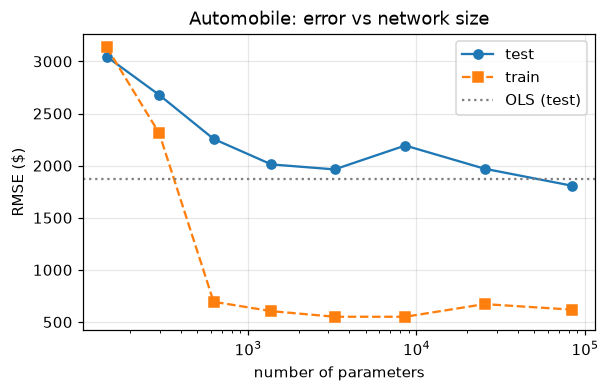

,params,rmse_train,rmse_test,rmse_test_sd,r2_test
model,,,,,
width 2,145,3135,3045,1205,0.834
width 4,297,2311,2678,867.2,0.8716
width 8,625,694.5,2256,233,0.9089
width 16,1377,604.3,2012,131.7,0.9276
width 32,3265,550.8,1964,115.7,0.931
width 64,8577,550.5,2193,46.28,0.9139
width 128,25345,672,1970,51.32,0.9305
width 256,83457,618.9,1808,35.8,0.9415


In [20]:
rwidth, _ = compare({f"width {w}": dict(widths=(w, w)) for w in [2, 4, 8, 16, 32, 64, 128, 256]}, real, epochs=R_EPOCHS)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(rwidth.params, to_usd(rwidth.mse_test), "o-", label="test")
ax.plot(rwidth.params, to_usd(rwidth.mse_train), "s--", label="train")
ax.axhline(to_usd(lin_mse), color="gray", ls=":", label="OLS (test)")
ax.set(xscale="log", xlabel="number of parameters", ylabel="RMSE ($)", title="Automobile: error vs network size")
ax.legend(); plt.show()
in_usd(rwidth)

**Observations** (with 41 test cars, differences of ~$100-200 are within the seed spread and the test-set noise).
- **Depth:** 1 to 4 hidden layers all land at $2,130-2,200. More depth gives nothing, since there is very little
  nonlinear structure to learn.
- **Activation:** all within ~$350 of each other. GELU and Sigmoid are slightly best (~$2,070), Tanh is worst ($2,418).
  Sigmoid doing well is the opposite of the toy problem: its slow, saturating training acts like a bit of
  regularization (it has the highest train error, $782), which helps when the problem is overfitting.
- **Size:** widths 2 and 4 underfit (train ≈ test, $2,300-3,100) and depend a lot on the seed. From width 8 the train
  error drops to ~$550-700 and stays there, so the net can memorize the training set. The test error doesn't get worse
  with size, though: it ends lowest at width 256 ($1,808, 83k parameters for 160 cars), just below OLS. There is no
  U-shaped curve here either: over-parameterized nets still generalize about as well.
- Caveats: as the lab asks, everything is compared on the test set, and with 41 cars that is noisy. To pick a model we
  would use cross-validation (done as a bonus in section 6). The data also contain several trims of the same
  model (near-duplicate rows), so a random split is a bit optimistic.

## 6. Bonus: cross-validation for model selection

This part isn't required by the lab, which asks for a train/test split. Everything above picks models by their test
error on just 41 cars, which is noisy, and it uses the test set for both choosing and judging. Here is the usual fix,
kept simple:

- 5-fold cross-validation on the **160 training cars only**, with folds stratified on price quintiles as before.
- The preprocessing (medians, one-hot columns, scaling) is fitted again inside each fold, on that fold's training part,
  so nothing leaks from the validation fold.
- A few candidates from above: OLS and some MLPs, with and without weight decay. Each MLP gets one seed per fold, 300 epochs,
  and we score the last epoch.
- We choose by mean CV RMSE. The test RMSE (same recipe, trained on all 160 cars) is shown only as a check, not used to choose.

In [21]:
from sklearn.model_selection import StratifiedKFold

def prep(c_a, p_a, c_b, p_b):
    # same preprocessing as in section 5, fitted on the (c_a, p_a) part only
    med = c_a.median(numeric_only=True)
    oh = lambda df: pd.get_dummies(df.fillna(med), columns=cat_cols, dtype=float)
    a = oh(c_a)
    b = oh(c_b).reindex(columns=a.columns, fill_value=0.0)
    fx, fy = StandardScaler().fit(a), StandardScaler().fit(p_a[:, None])
    splits = (col(fx.transform(a)), col(fy.transform(p_a[:, None])),
              col(fx.transform(b)), col(fy.transform(p_b[:, None])))
    return splits, fy.scale_[0]

def rmse_usd(kw, splits, usd):
    # train on splits[0:2], return the RMSE in $ on splits[2:4]; kw=None means OLS
    if kw is None:
        pred = LinearRegression().fit(splits[0], splits[1]).predict(splits[2])
        mse = F.mse_loss(torch.tensor(pred, dtype=torch.float32), splits[3]).item()
    else:
        kw = dict(kw)
        wd = kw.pop("wd", 0.0)
        torch.manual_seed(0)
        m = FeedForward(splits[0].shape[1], **kw)
        mse = fit(m, splits, epochs=R_EPOCHS, wd=wd).mse_test.iloc[-1]
    return np.sqrt(mse) * usd

candidates = {"OLS": None,
              "2x64": dict(widths=(64, 64)),
              "2x64, wd 0.01": dict(widths=(64, 64), wd=1e-2),
              "2x64, wd 0.1": dict(widths=(64, 64), wd=1e-1),
              "3x128": dict(widths=big),
              "2x256": dict(widths=(256, 256))}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for a, b in folds.split(c_tr, pd.qcut(p_tr, 5, labels=False)):
    splits, usd = prep(c_tr.iloc[a], p_tr[a], c_tr.iloc[b], p_tr[b])
    rows.append({name: rmse_usd(kw, splits, usd) for name, kw in candidates.items()})
cv = pd.DataFrame(rows)  # one row per fold, RMSE in $

cv_res = pd.DataFrame({"cv_rmse": cv.mean(), "cv_rmse_sd": cv.std(),
                       "test_rmse": {name: rmse_usd(kw, real, USD) for name, kw in candidates.items()}})
cv_res = cv_res.sort_values("cv_rmse")
print("chosen by CV:", cv_res.index[0])
cv_res

chosen by CV: 2x256


,cv_rmse,cv_rmse_sd,test_rmse
2x256,2324,905.4,1848
"2x64, wd 0.1",2454,1045,1907
3x128,2588,1076,2165
"2x64, wd 0.01",2645,1035,2266
2x64,2743,929.8,2238
OLS,3370,1419,1868


**Observations.**
- CV chooses **2x256** (CV RMSE ≈ $2,320), followed by **2x64 with $\lambda = 0.1$** (≈ $2,450). That is the same
  picture as the test-set comparisons above: a wide net or weight decay helps the 2×64 net. This time, though, the
  choice is made without the test set. The test RMSE of the chosen model ($1,848) is the best in the table.
- The ±$900-1,400 spread looks large, but most of it comes from one fold that is hard for every model ($3,900-5,700).
  Fold by fold the ranking is quite stable: 2x256 is first in 4 of the 5 folds and second in the other.
- The biggest change is **OLS**. On the single test split it looked as good as the best net ($1,868), but in CV it is
  last in 4 of 5 folds ($3,370). With 128 training cars per fold and 67 mostly one-hot inputs, plain least squares is
  unstable, and our one test split happened to be kind to it. This is the kind of luck a 41-car test set can't show.
  A regularized linear model (ridge) would be the fairer baseline.
- CV errors are higher than test errors overall: each fold trains on 128 instead of 160 cars, and one fold is hard.

## Summary

- An MLP trained with MSE and Adam fits a low-order polynomial down to the noise level in a few dozen epochs. Outside
  the training range a ReLU net just continues linearly, so it only learns $f$ where it has data.
- Weight decay only pays off when the model overfits. On the toy data it just adds bias. On Automobile (160 cars,
  67 inputs) the net overfits a lot, and $\lambda = 0.1$ cuts the test RMSE of the 2×64 net from $2,193 to $1,905.
- Capacity has to match the target. A cubic needs ~100 parameters, an order-21 polynomial needs a deeper/wider net,
  and depth adds capacity more cheaply than width.
- Activations matter mainly through optimization: Sigmoid is the worst on the toy data, ReLU-type activations train
  fastest, and smooth ones help a little on smooth 1-D targets. On the small real dataset the differences are within noise.
- On Automobile the MLP reaches R² ≈ 0.91-0.94 (test RMSE ≈ $1,800-2,200), about the same as linear regression
  ($1,868): price is mostly linear in the car's specs, and with this little data there's no room for a net to do better.
- Bonus (section 6): 5-fold cross-validation on the training cars picks a wide net (2×256), with weight decay a close
  second, and shows that plain OLS only looked competitive thanks to a lucky test split.